# SegNet – phân đoạn các phần của bàn tay từ ảnh độ sâu — bản PyTorch

Chuyển từ notebook Keras gốc: `Example/examples/5. Others/1_segnet.ipynb`.
Giữ nguyên dữ liệu, kiến trúc, hàm mất mát, optimizer, learning rate, batch size; chỉ thay framework.

**Đối chiếu Keras → PyTorch trong notebook này**

| Keras (gốc) | PyTorch (bản chuyển) |
|---|---|
| `skimage.io.imread` + `resize(order=0)` | `PIL.Image.open` + `resize(..., Image.NEAREST)` (không cần scikit-image) |
| nhãn one-hot `(N, 96*96, 7)` | nhãn số nguyên `(N, 96, 96)` (chỉ số lớp của từng điểm ảnh) |
| `Conv2D` + `BatchNormalization()` + `Activation('relu')` | `nn.Conv2d` + `nn.BatchNorm2d(eps=1e-3, momentum=0.01)` + `nn.ReLU()` (eps/momentum chỉnh theo mặc định Keras) |
| `MaxPooling2D()` / `UpSampling2D()` | `nn.MaxPool2d(2)` / `nn.Upsample(scale_factor=2, mode='nearest')` |
| `Reshape((7, 96*96))` → `Permute((2,1))` → `softmax` + `categorical_crossentropy` | giữ output `(B, 7, 96, 96)` và dùng `nn.CrossEntropyLoss()` theo trục kênh – xem ghi chú bên dưới |
| `Adam(lr=0.0001)`, `batch_size=8`, `epochs=15` | `torch.optim.Adam(lr=1e-4)`, batch 8, `EPOCHS` (mặc định 3 trên CPU) |

> **Ghi chú về lớp `Reshape` của bản gốc:** code SegNet gốc được viết cho Keras/Theano dạng *channels-first* (tensor
> `(7, 96, 96)`), nên `Reshape((7, 96*96))` đúng. Notebook của thầy chạy với *channels-last* (tensor `(96, 96, 7)`), khi đó
> `Reshape((7, 96*96))` sắp xếp lại bộ nhớ theo thứ tự hàng, **không** phải hoán vị trục, nên giá trị "lớp k của điểm ảnh p"
> bị lấy từ một vị trí/kênh khác. Bản PyTorch dùng trực tiếp output `(B, 7, H, W)` với `CrossEntropyLoss` theo trục kênh,
> đúng với ý nghĩa phân đoạn từng điểm ảnh.
>
> **Cấu hình chạy trên CPU:** mỗi epoch ~9 phút (29,4 triệu tham số) nên đặt `EPOCHS = 3`; bản gốc 15 epoch.

# Import libraries

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Thư mục gốc bài nộp = thư mục cha gần nhất có chứa "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT =", ROOT, "| device =", DEVICE, "| torch", torch.__version__)

import os
from PIL import Image

np.random.seed(2024); torch.manual_seed(2024)
n_classes = 7
kernel = 3
img_h = img_w = 96
EPOCHS = 3   # Keras gốc: 15

ROOT = d:\SGU\deep-learning\Tuan13\BTL03_TranQuocAn_3123411009 | device = cpu | torch 2.14.0+cpu


In [2]:
def summary(model, input_size, keras_params=None):
    """Tương đương model.summary() của Keras: tên lớp, output shape, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0 and name:
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, name=name: rows.append(
                    (name, type(mod).__name__, tuple(o.shape) if torch.is_tensor(o) else "-",
                     sum(p.numel() for p in mod.parameters(recurse=False))))))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    print(f"{'Layer':<22}{'Type':<16}{'Output shape':<26}{'Param #':>12}")
    print("=" * 76)
    for n, t, s, p in rows:
        print(f"{n:<22}{t:<16}{str(s):<26}{p:>12,}")
    total = sum(p.numel() for p in model.parameters())
    print("=" * 76)
    print(f"Total params: {total:,}" + (f"   (Keras gốc: {keras_params:,})" if keras_params else ""))

def run_epoch(model, loader, loss_fn, metric_fn=None, optimizer=None, augment=None):
    """1 epoch train (có optimizer) hoặc đánh giá (optimizer=None). Trả về (loss, metric) trung bình theo mẫu."""
    training = optimizer is not None
    model.train(training)
    tot_loss, tot_metric, n = 0.0, 0.0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None and training:
                xb = augment(xb)
            out = model(xb)                      # forward
            loss = loss_fn(out, yb)              # loss
            if training:
                optimizer.zero_grad()            # xoá gradient cũ
                loss.backward()                  # backpropagation
                optimizer.step()                 # cập nhật trọng số
            tot_loss += loss.item() * len(xb)
            if metric_fn is not None:
                tot_metric += metric_fn(out.detach(), yb) * len(xb)
            n += len(xb)
    return tot_loss / n, (tot_metric / n if metric_fn is not None else None)


def fit(model, train_loader, val_loader, epochs, optimizer, loss_fn, metric_fn=None, metric_name="accuracy",
        augment=None):
    """Tương đương model.fit(..., validation_data=...): in log mỗi epoch, trả về history."""
    history = {"loss": [], "val_loss": [], metric_name: [], "val_" + metric_name: []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_m = run_epoch(model, train_loader, loss_fn, metric_fn, optimizer, augment)
        va_loss, va_m = run_epoch(model, val_loader, loss_fn, metric_fn)
        history["loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history[metric_name].append(tr_m); history["val_" + metric_name].append(va_m)
        msg = f"Epoch {ep}/{epochs} - {time.time() - t0:.0f}s - loss: {tr_loss:.4f}"
        if metric_fn is not None:
            msg += f" - {metric_name}: {tr_m:.4f}"
        msg += f" - val_loss: {va_loss:.4f}"
        if metric_fn is not None:
            msg += f" - val_{metric_name}: {va_m:.4f}"
        print(msg, flush=True)
    return history


def accuracy(out, y):
    """Độ chính xác phân loại: so argmax của logits với nhãn số nguyên."""
    return (out.argmax(1) == y).float().mean().item()


def plot_history(history, metric_name="accuracy"):
    keys = [("loss", "val_loss")] + ([(metric_name, "val_" + metric_name)] if history[metric_name][0] is not None else [])
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 3.8))
    axes = np.atleast_1d(axes)
    for ax, (a, b) in zip(axes, keys):
        ax.plot(range(1, len(history[a]) + 1), history[a], marker="o", label="train")
        ax.plot(range(1, len(history[b]) + 1), history[b], marker="o", label="validation")
        ax.set_xlabel("epoch"); ax.set_ylabel(a); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.show()

# (1) Data
#### Hand images: https://drive.google.com/file/d/1MRiBnDW9dE7mNb5bL-jzhmtTd2CSklvL/view?usp=sharing

In [3]:
# màu xám trong ảnh nhãn -> chỉ số lớp (giống gray2classes của bản gốc)
CLASS_COLORS = {255: 0,   # palm
                43: 1,    # finger 1
                85: 2,    # finger 2
                128: 3,   # finger 3
                170: 4,   # finger 4
                212: 5,   # finger 5
                0: 6}     # background
LUT = np.full(256, 255, dtype=np.uint8)            # màu lạ -> 255 (bỏ qua khi tính loss)
for color, cls in CLASS_COLORS.items():
    LUT[color] = cls


def prepare_segnet_data(root_path):
    loi = sorted(os.listdir(root_path))
    data_x = np.zeros((len(loi), 1, img_h, img_w), dtype=np.float32)
    data_y = np.zeros((len(loi), img_h, img_w), dtype=np.int64)
    for im_ind, fn in enumerate(loi):
        fn = os.path.join(root_path, fn)
        labels_fn = fn.replace("depth", "labels")
        img = Image.open(fn).resize((img_w, img_h), Image.NEAREST)        # order=0
        lbl = Image.open(labels_fn).resize((img_w, img_h), Image.NEAREST)
        data_x[im_ind, 0] = np.asarray(img, dtype=np.float32)            # giữ thang 0..255 như bản gốc
        data_y[im_ind] = LUT[np.asarray(lbl)]
    return data_x, data_y


x_train, y_train = prepare_segnet_data(str(DATA / "segnet" / "train" / "depth"))
x_test, y_test = prepare_segnet_data(str(DATA / "segnet" / "test" / "depth"))
print("x_train", x_train.shape, "| y_train", y_train.shape, "| x_test", x_test.shape)
print("số điểm ảnh màu lạ:", int((y_train == 255).sum() + (y_test == 255).sum()))

x_train (2450, 1, 96, 96) | y_train (2450, 96, 96) | x_test (1050, 1, 96, 96)
số điểm ảnh màu lạ: 48455


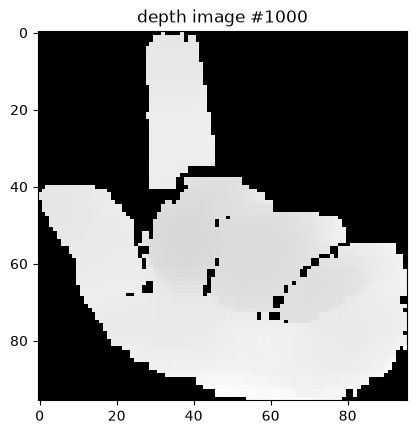

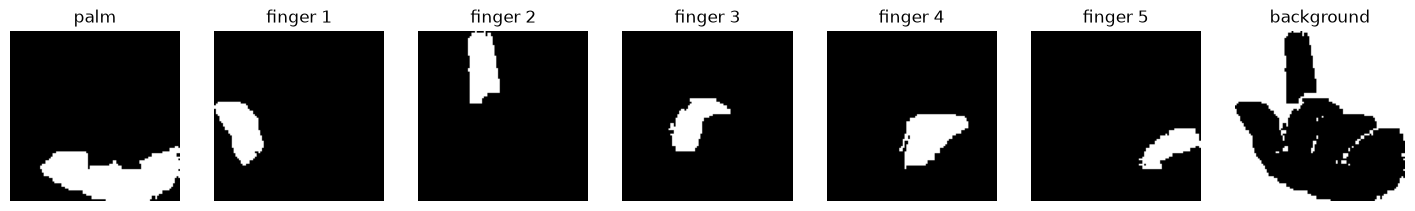

In [4]:
plt.imshow(x_test[1000, 0], cmap="gray"); plt.title("depth image #1000"); plt.show()
plt.figure(figsize=(18, 3))
names = ["palm", "finger 1", "finger 2", "finger 3", "finger 4", "finger 5", "background"]
for c in range(n_classes):
    plt.subplot(1, 7, c + 1); plt.imshow(y_test[1000] == c, cmap="gray"); plt.title(names[c]); plt.axis("off")
plt.show()
train_loader = DataLoader(TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train)), batch_size=8, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test)), batch_size=16)

# (2) Declare model

In [5]:
def cbr(cin, cout, k=kernel):
    """Conv2D + BatchNormalization + ReLU (BN chỉnh eps/momentum theo mặc định Keras)."""
    return [nn.Conv2d(cin, cout, k, padding=k // 2), nn.BatchNorm2d(cout, eps=1e-3, momentum=0.01), nn.ReLU()]


encoding_layers = (cbr(1, 64) + cbr(64, 64) + [nn.MaxPool2d(2)]
                   + cbr(64, 128) + cbr(128, 128) + [nn.MaxPool2d(2)]
                   + cbr(128, 256) + cbr(256, 256) + cbr(256, 256) + [nn.MaxPool2d(2)]
                   + cbr(256, 512) + cbr(512, 512) + cbr(512, 512) + [nn.MaxPool2d(2)]
                   + cbr(512, 512) + cbr(512, 512) + cbr(512, 512) + [nn.MaxPool2d(2)])   # 96 -> 3
up = lambda: nn.Upsample(scale_factor=2, mode="nearest")                                 # UpSampling2D()
decoding_layers = ([up()] + cbr(512, 512) + cbr(512, 512) + cbr(512, 512)
                   + [up()] + cbr(512, 512) + cbr(512, 512) + cbr(512, 256)
                   + [up()] + cbr(256, 256) + cbr(256, 256) + cbr(256, 128)
                   + [up()] + cbr(128, 128) + cbr(128, 64)
                   + [up()] + cbr(64, 64)
                   + [nn.Conv2d(64, n_classes, 1), nn.BatchNorm2d(n_classes, eps=1e-3, momentum=0.01)])   # 3 -> 96

autoencoder = nn.Sequential(*encoding_layers, *decoding_layers).to(DEVICE)   # output: logits (B, 7, 96, 96)
summary(autoencoder, (1, img_h, img_w), keras_params=29_442_325)

Layer                 Type            Output shape                   Param #
0                     Conv2d          (1, 64, 96, 96)                    640
1                     BatchNorm2d     (1, 64, 96, 96)                    128
2                     ReLU            (1, 64, 96, 96)                      0
3                     Conv2d          (1, 64, 96, 96)                 36,928
4                     BatchNorm2d     (1, 64, 96, 96)                    128
5                     ReLU            (1, 64, 96, 96)                      0
6                     MaxPool2d       (1, 64, 48, 48)                      0
7                     Conv2d          (1, 128, 48, 48)                73,856
8                     BatchNorm2d     (1, 128, 48, 48)                   256
9                     ReLU            (1, 128, 48, 48)                     0
10                    Conv2d          (1, 128, 48, 48)               147,584
11                    BatchNorm2d     (1, 128, 48, 48)                   256

# (3) Train defined model

Epoch 1/3 - 524s - loss: 1.1779 - accuracy: 0.6765 - val_loss: 1.3815 - val_accuracy: 0.6064


Epoch 2/3 - 542s - loss: 0.9027 - accuracy: 0.7990 - val_loss: 0.9588 - val_accuracy: 0.7644


Epoch 3/3 - 510s - loss: 0.7787 - accuracy: 0.8432 - val_loss: 0.9014 - val_accuracy: 0.7817


> training time: 1575.4s


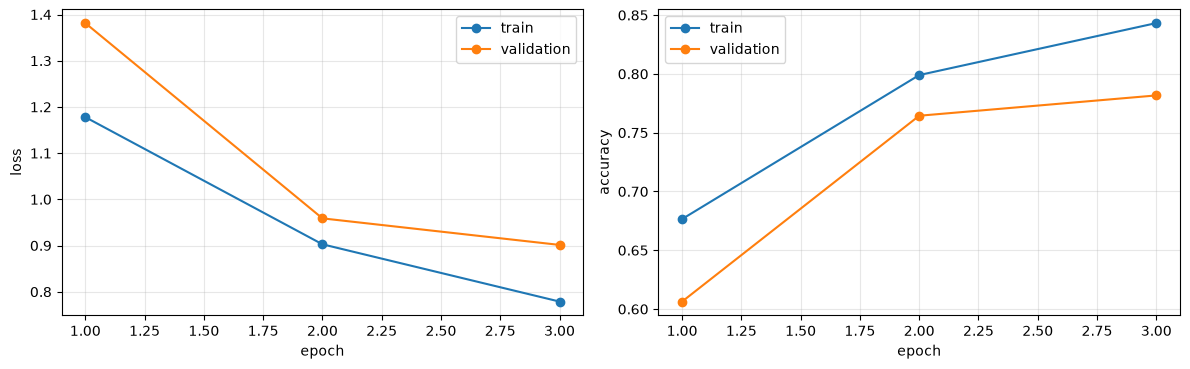

In [6]:
loss_fn = nn.CrossEntropyLoss(ignore_index=255)       # categorical_crossentropy theo từng điểm ảnh


def pixel_accuracy(out, y):
    """Giống metric 'accuracy' của bản gốc: tỉ lệ điểm ảnh (kể cả nền) được gán đúng lớp."""
    valid = y != 255
    return ((out.argmax(1) == y) & valid).float().sum().item() / valid.sum().item()


optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.0001)
start_time = time.time()
history = fit(autoencoder, train_loader, test_loader, EPOCHS, optimizer, loss_fn, pixel_accuracy)
print("> training time: %.1fs" % (time.time() - start_time))
plot_history(history)

# (4) Evaluate trained model

In [7]:
test_loss, test_acc = run_epoch(autoencoder, test_loader, loss_fn, pixel_accuracy)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 0.9013868109385172
Test accuracy: 0.7816806369623094


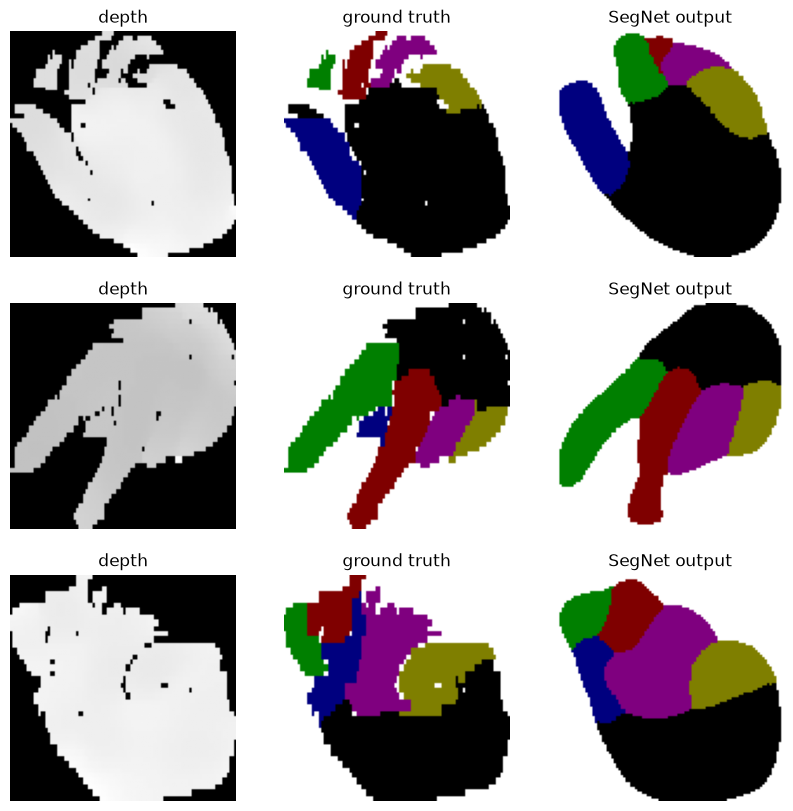

In [8]:
PALETTE = np.array([[0, 0, 0], [0, 0, .5], [0, .5, 0], [.5, 0, 0], [.5, 0, .5], [.5, .5, 0], [1, 1, 1]])   # class_to_rgb


autoencoder.eval()
idx = np.random.choice(len(x_test), 3, replace=False)
with torch.no_grad():
    pred = autoencoder(torch.from_numpy(x_test[idx]).to(DEVICE)).argmax(1).cpu().numpy()
plt.figure(figsize=(10, 10))
for r, i in enumerate(idx):
    for c, (img, t) in enumerate([(x_test[i, 0], "depth"), (PALETTE[y_test[i]], "ground truth"), (PALETTE[pred[r]], "SegNet output")]):
        plt.subplot(3, 3, r * 3 + c + 1); plt.imshow(img, cmap="gray" if c == 0 else None); plt.title(t); plt.axis("off")
plt.show()